# Comparing mobile-game campaigns on cost and player revenue

This notebook compares eight campaigns (A–H) using cost per day-7 payer, funnel rates, and revenue per registered player over several time windows. It also sketches an experiment and a cohort query.

The four CSV inputs are in this repository's `data/` folder. They are records from a mobile-game hiring assessment, anonymized for publication. Treat the reported campaign values as exploratory until the cost period, attribution window, cohort maturity, joins, and statistical analysis have been checked. The campaign comparisons are observational; they do not show that a campaign caused higher-value users.


## Table of Contents

0. [Prepare the data](#data-prep)
1. [Short-term campaign comparison](#task1)
2. [Funnel rates and revenue by time window](#task2)
3. [Compare day-7 payment distributions for Campaigns E and H](#task3)
4. [Proposed randomized creative test](#task4)
5. [Cohort revenue query](#task5)
6. [Summary and next steps](#conclusions)


<a id='data-prep'></a>
## 0. Prepare the data

This notebook uses pandas for table operations, SciPy and statsmodels for statistical calculations, and matplotlib/seaborn for charts. It also uses SQLite for the cohort example. The four CSV inputs are in this project's `data/` folder. The original assessment notebooks and PDF are not included.

In [1]:
# Libraries
import pandas as pd
import numpy as np
from scipy import stats
from statsmodels.stats.power import zt_ind_solve_power
from statsmodels.stats.proportion import proportion_effectsize

import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

import sqlite3

from pathlib import Path

# Supports launching Jupyter from this folder or the repository root.
DATA_DIR = Path('data')
if not DATA_DIR.exists():
    DATA_DIR = Path('1-marketing-analytics-for-mobile-game/data')

# Chart style shared with the other portfolio cases.
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'figure.figsize': (12, 6),
})
GROUP_COLORS = {'meets': '#176b8c', 'above': '#b14632'}


The next cell loads the four tables and links user registration records to in-game payment and activity logs. This gives one view of the user journey, from acquisition to monetization.


In [2]:
registration = pd.read_csv(DATA_DIR / 'registration.csv')
payment = pd.read_csv(DATA_DIR / 'payment.csv')
tutorial = pd.read_csv(DATA_DIR / 'tutorial.csv')
ad_data = pd.read_csv(DATA_DIR / 'ad_data.csv')

print("Dataset Overview:")
print(f"Registration data: {registration.shape[0]:,} rows")
print(f"Payment data: {payment.shape[0]:,} rows")
print(f"Tutorial data: {tutorial.shape[0]:,} rows")
print(f"Ad campaign data: {ad_data.shape[0]:,} rows")

for df in [registration, payment, tutorial, ad_data]:
    df['date'] = pd.to_datetime(df['date'])

# Event timestamps are Unix epoch seconds; keep the raw column and add parsed columns.
registration['reg_ts'] = pd.to_datetime(registration['ts'], unit='s')
tutorial['tut_ts'] = pd.to_datetime(tutorial['ts'], unit='s')
payment['pay_ts'] = pd.to_datetime(payment['ts'], unit='s')

# The source file misspells the campaign column.
ad_data = ad_data.rename(columns={'capmaign': 'campaign'})

print("\nVerifying timestamp conversions:")
print("Registration 'reg_ts' dtype:", registration['reg_ts'].dtype)
print("Tutorial 'tut_ts' dtype:", tutorial['tut_ts'].dtype)
print("Payment 'pay_ts' dtype:", payment['pay_ts'].dtype)
print("Ad Data 'date' dtype:", ad_data['date'].dtype)


Dataset Overview:
Registration data: 43,830 rows
Payment data: 29,444 rows
Tutorial data: 21,299 rows
Ad campaign data: 41 rows

Verifying timestamp conversions:
Registration 'reg_ts' dtype: datetime64[us]
Tutorial 'tut_ts' dtype: datetime64[ns]
Payment 'pay_ts' dtype: datetime64[us]
Ad Data 'date' dtype: datetime64[us]


In [3]:
def quick_analysis(name, df):
    """Quick dataset analysis with clean formatting"""
    print(f"\n### {name} ###")

    print("\nSample Data:")
    display(df.head())

    print("\nSummary Statistics:")
    display(df.describe())

    missing = df.isnull().sum()
    if missing.sum() > 0:
        print("\nMissing Values:")
        display(missing[missing > 0].to_frame('Missing Count'))
    else:
        print("\nNo missing values")

datasets = [
    ('Registration', registration),
    ('Payment', payment),
    ('Tutorial', tutorial),
    ('Ad Campaign', ad_data)
]

for name, data in datasets:
    quick_analysis(name, data)


### Registration ###

Sample Data:


,date,ts,id,campaign,channel,country,reg_ts
0,2020-05-01,1588347131,13,campaign_A,paid,us,2020-05-01 15:32:11
1,2020-05-01,1588339079,624,campaign_A,paid,us,2020-05-01 13:17:59
2,2020-05-01,1588320063,625,campaign_A,paid,us,2020-05-01 08:01:03
3,2020-05-01,1588309663,626,campaign_A,paid,us,2020-05-01 05:07:43
4,2020-05-01,1588311876,627,campaign_A,paid,us,2020-05-01 05:44:36



Summary Statistics:


,date,ts,id,reg_ts
count,43830,4.383000e+04,43830.000000,43830
mean,2020-05-19 06:17:47.433265,1.589913e+09,21927.500000,2020-05-19 18:36:29.157905
min,2020-05-01 00:00:00,1.588291e+09,13.000000,2020-05-01 00:02:32
25%,2020-05-13 00:00:00,1.589398e+09,10970.250000,2020-05-13 19:32:58.500000
50%,2020-05-20 00:00:00,1.590010e+09,21927.500000,2020-05-20 21:32:22
75%,2020-05-27 00:00:00,1.590553e+09,32884.750000,2020-05-27 04:14:43.500000
max,2020-05-31 00:00:00,1.590970e+09,43842.000000,2020-05-31 23:59:31
std,NaN,7.531963e+05,12652.775486,NaN



Missing Values:


,Missing Count
campaign,6686


... (9 outputs left out)

,date,campaign,costs,impressions,clicks
0,2020-05-01,campaign_A,1674.0,13999,5892
1,2020-05-02,campaign_A,1771.0,13401,4208
2,2020-05-03,campaign_A,2396.0,8496,5683
3,2020-05-03,campaign_C,1863.0,7595,3119
4,2020-05-04,campaign_B,145.0,1001,550



Summary Statistics:


,date,costs,impressions,clicks
count,41,41.000000,41.000000,41.000000
mean,2020-05-15 09:57:04.390244,2210.956098,12468.317073,5423.292683
min,2020-05-01 00:00:00,145.000000,1001.000000,498.000000
25%,2020-05-07 00:00:00,1690.000000,6814.000000,2744.000000
50%,2020-05-17 00:00:00,2045.000000,11849.000000,5331.000000
75%,2020-05-22 00:00:00,2454.100000,15473.000000,6986.000000
max,2020-05-31 00:00:00,5144.500000,32221.000000,13837.000000
std,NaN,1193.011966,7913.958101,3533.086924



No missing values


### Initial data checks

The notebook uses four inputs:

- **Registration:** player ID, campaign, channel, country, and registration time. Some campaign values are missing.
- **Payment:** player ID, payment amount, and payment time.
- **Tutorial:** player ID and tutorial-completion time.
- **Ad campaign:** campaign-level costs, impressions, clicks, and date.

The code converts event timestamps to datetimes and renames a misspelled campaign field. Before interpreting results, verify timestamp units and timezone, missing campaign handling, duplicate IDs, join cardinality, and coverage of each observation window.

<a id='task1'></a>
## 1. Short-term campaign comparison

The notebook defines an initial screening rule: campaign cost per day-7 payer (CPP) at or below $50 is labeled “meets target.” A day-7 payer is a registered user with a payment within 168 hours of registration.

In the outputs below the two groups are labeled **meets target (CPP ≤ $50)** and **above target (CPP > $50)**. The screen counts any payment up to 168 hours after registration; it does not exclude payments logged before registration.

This is a descriptive comparison, not a causal estimate. Before using CPP for a decision, align the cost dates with the registration cohort and confirm that each user has a complete seven-day observation window.

In [4]:
merged_reg_pay_df = pd.merge(registration, payment, on='id', how='inner')

# Key metrics
merged_reg_pay_df['lifetime'] = merged_reg_pay_df['pay_ts'] - merged_reg_pay_df['reg_ts']

day7_payments_df = merged_reg_pay_df[merged_reg_pay_df['lifetime'] <= pd.Timedelta(days=7)]
day7_payer_ids = day7_payments_df['id'].unique() # Day 7 payers (within 7 days = 168 hours)

day7_payers_registration_df = registration[registration['id'].isin(day7_payer_ids)]

day7_payers_count = day7_payers_registration_df.groupby('campaign')['id'].nunique()

campaign_costs = ad_data.groupby('campaign')['costs'].sum()

cost_per_payer = campaign_costs / day7_payers_count

# effective VS ineffective
effectiveness_results = pd.DataFrame({
    'CPP': cost_per_payer,
    'Day7_Payers': day7_payers_count
})

effectiveness_results['effective'] = effectiveness_results['CPP'] <= 50
effectiveness_results['status'] = effectiveness_results['effective'].map({True: 'Meets target', False: 'Above target'})

print("Campaign CPP screening results:")
print("=" * 50)
print(effectiveness_results.to_string())

effective_campaigns = effectiveness_results[effectiveness_results['effective'] == True].index.tolist()
ineffective_campaigns = effectiveness_results[effectiveness_results['effective'] == False].index.tolist()

print(f"\nCampaigns meeting the target (CPP ≤ $50): {effective_campaigns}")
print(f"Campaigns above the target (CPP > $50): {ineffective_campaigns}")

Campaign CPP screening results:
             CPP  Day7_Payers  effective        status
campaign                                              
campaign_A  59.0           99      False  Above target
campaign_B  40.0            9       True  Meets target
campaign_C  71.8          214      False  Above target
campaign_D  58.3           13      False  Above target
campaign_E  43.7          463       True  Meets target
campaign_F  73.9           79      False  Above target
campaign_G  44.8          268       True  Meets target
campaign_H  54.5          555      False  Above target

Campaigns meeting the target (CPP ≤ $50): ['campaign_B', 'campaign_E', 'campaign_G']
Campaigns above the target (CPP > $50): ['campaign_A', 'campaign_C', 'campaign_D', 'campaign_F', 'campaign_H']


### Reported CPP output

The output above labels Campaigns B, E, and G as meeting the $50 CPP threshold: $40.00 per day-7 payer for Campaign B, $43.70 for Campaign E, and $44.80 for Campaign G. These values depend on the current cost aggregation and payer definition; validate that costs and users cover the same campaigns and dates before treating them as comparable.

CPP alone does not measure long-term value or incremental return. Use this result as an initial screen, not as a budget recommendation.

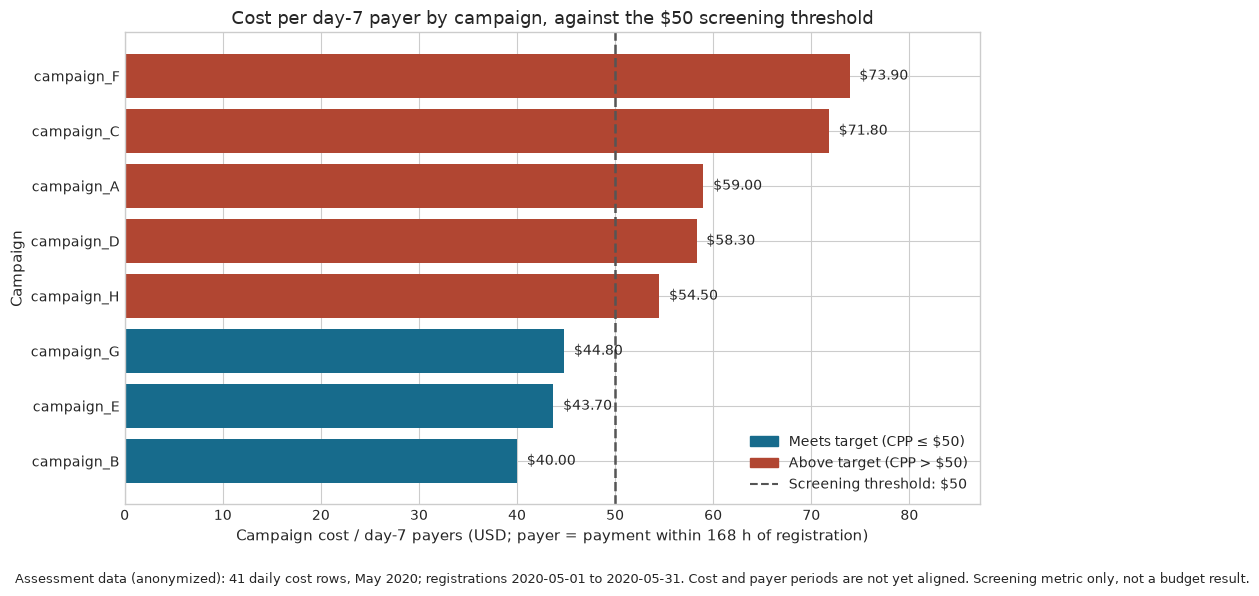

In [5]:
def create_cpp_chart(effectiveness_results):
    sorted_results = effectiveness_results.sort_values('CPP')
    fig, ax = plt.subplots(figsize=(10, 6))
    colors = [GROUP_COLORS['meets'] if cpp <= 50 else GROUP_COLORS['above']
              for cpp in sorted_results['CPP']]
    bars = ax.barh(range(len(sorted_results)), sorted_results['CPP'], color=colors)

    ax.axvline(50, color='#555555', linestyle='--', linewidth=1.8)
    for i, (idx, row) in enumerate(sorted_results.iterrows()):
        ax.text(row['CPP'] + 1, i, f"${row['CPP']:.2f}", va='center', fontsize=10)

    ax.set_title('Cost per day-7 payer by campaign, against the $50 screening threshold')
    ax.set_xlabel('Campaign cost / day-7 payers (USD; payer = payment within 168 h of registration)')
    ax.set_ylabel('Campaign')
    ax.set_yticks(range(len(sorted_results)), sorted_results.index)
    ax.set_xlim(0, max(sorted_results['CPP']) * 1.18)
    ax.legend(handles=[
        Patch(color=GROUP_COLORS['meets'], label='Meets target (CPP ≤ $50)'),
        Patch(color=GROUP_COLORS['above'], label='Above target (CPP > $50)'),
        plt.Line2D([0], [0], color='#555555', linestyle='--', label='Screening threshold: $50'),
    ], loc='lower right', frameon=False)
    fig.text(0.02, 0.02,
             'Assessment data (anonymized): 41 daily cost rows, May 2020; registrations 2020-05-01 to 2020-05-31. '
             'Cost and payer periods are not yet aligned. Screening metric only, not a budget result.',
             fontsize=9)
    fig.tight_layout(rect=(0, 0.06, 1, 1))
    return fig


fig = create_cpp_chart(effectiveness_results)
plt.show()


## 2. Funnel rates and revenue by time window

The next section compares click, registration, tutorial-completion, and payment measures across campaigns labeled above or below the CPP threshold. It also calculates revenue per registered user over several time windows.

These are descriptive comparisons. The grouping reuses the CPP labels, so differences may reflect audience and campaign mix rather than a campaign effect. Check denominators and ensure users have enough follow-up time for each revenue window.

In [6]:
effective_ad_data = ad_data[ad_data['campaign'].isin(effective_campaigns)]
ineffective_ad_data = ad_data[ad_data['campaign'].isin(ineffective_campaigns)]
effective_registration = registration[registration['campaign'].isin(effective_campaigns)]
ineffective_registration = registration[registration['campaign'].isin(ineffective_campaigns)]

effective_tutorial = tutorial[tutorial['id'].isin(effective_registration['id'])]
ineffective_tutorial = tutorial[tutorial['id'].isin(ineffective_registration['id'])]

day7_payers_effective_reg_df = registration[
    (registration['campaign'].isin(effective_campaigns)) &
    (registration['id'].isin(day7_payers_registration_df['id']))
]
day7_payers_ineffective_reg_df = registration[
    (registration['campaign'].isin(ineffective_campaigns)) &
    (registration['id'].isin(day7_payers_registration_df['id']))
]

effective_impressions = effective_ad_data['impressions'].sum()
effective_clicks = effective_ad_data['clicks'].sum()
ineffective_impressions = ineffective_ad_data['impressions'].sum()
ineffective_clicks = ineffective_ad_data['clicks'].sum()

effective_ctr = (effective_clicks / effective_impressions) if effective_impressions > 0 else 0
ineffective_ctr = (ineffective_clicks / ineffective_impressions) if ineffective_impressions > 0 else 0

# Calculate product funnel metrics
effective_registrations = effective_registration['id'].nunique()
ineffective_registrations = ineffective_registration['id'].nunique()

effective_reg_rate = (effective_registrations / effective_clicks) if effective_clicks > 0 else 0
ineffective_reg_rate = (ineffective_registrations / ineffective_clicks) if ineffective_clicks > 0 else 0

effective_tutorial_completions = effective_tutorial['id'].nunique()
ineffective_tutorial_completions = ineffective_tutorial['id'].nunique()

effective_tut_comp_rate = (effective_tutorial_completions / effective_registrations) if effective_registrations > 0 else 0
ineffective_tut_comp_rate = (ineffective_tutorial_completions / ineffective_registrations) if ineffective_registrations > 0 else 0

effective_day7_payers = day7_payers_effective_reg_df['id'].nunique()
ineffective_day7_payers = day7_payers_ineffective_reg_df['id'].nunique()

effective_day7_payer_rate = (effective_day7_payers / effective_registrations) if effective_registrations > 0 else 0
ineffective_day7_payer_rate = (ineffective_day7_payers / ineffective_registrations) if ineffective_registrations > 0 else 0

effective_overall_conversion = (effective_day7_payers / effective_clicks) if effective_clicks > 0 else 0
ineffective_overall_conversion = (ineffective_day7_payers / ineffective_clicks) if ineffective_clicks > 0 else 0

# Funnel comparison df
funnel_comparison = pd.DataFrame({
    'Campaign Group': ['Meets target (CPP ≤ $50)', 'Above target (CPP > $50)'],
    'Impressions': [effective_impressions, ineffective_impressions],
    'Clicks': [effective_clicks, ineffective_clicks],
    'CTR': [effective_ctr, ineffective_ctr],
    'Registrations': [effective_registrations, ineffective_registrations],
    'Registration Rate': [effective_reg_rate, ineffective_reg_rate],
    'Tutorial Completions': [effective_tutorial_completions, ineffective_tutorial_completions],
    'Tutorial Completion Rate': [effective_tut_comp_rate, ineffective_tut_comp_rate],
    'Day 7 Payers': [effective_day7_payers, ineffective_day7_payers],
    'Day 7 Payer Rate': [effective_day7_payer_rate, ineffective_day7_payer_rate],
    'Overall Conversion (Clicks→Pay)': [effective_overall_conversion, ineffective_overall_conversion]
})

print("Funnel analysis by CPP screening group")
print("=" * 50)
print(funnel_comparison.to_string(index=False))

Funnel analysis by CPP screening group


          Campaign Group  Impressions  Clicks      CTR  Registrations  Registration Rate  Tutorial Completions  Tutorial Completion Rate  Day 7 Payers  Day 7 Payer Rate  Overall Conversion (Clicks→Pay)
Meets target (CPP ≤ $50)       201276   88525 0.439819          15067           0.170201                  8114                  0.538528           740          0.049114                         0.008359
Above target (CPP > $50)       309925  133830 0.431814          22077           0.164963                 10414                  0.471713           960          0.043484                         0.007173


### Reported funnel results

The output above reports tutorial-completion rates of 53.9% for the “meets target” group and 47.2% for the “above target” group. Verify the group definitions and denominator used for each funnel step before interpreting this gap.

A difference in tutorial completion may help identify where to investigate user experience. This analysis does not show that tutorial completion caused higher monetization.

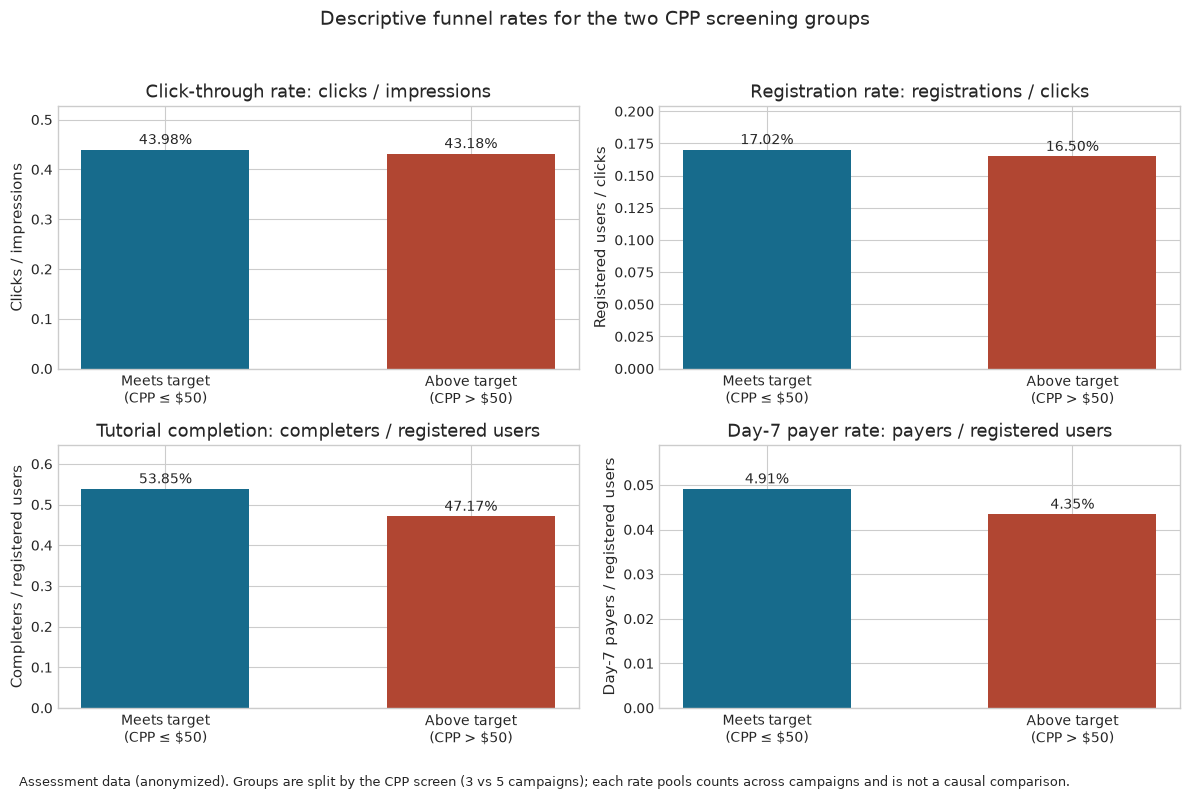

In [7]:
group_labels = ['Meets target\n(CPP ≤ $50)', 'Above target\n(CPP > $50)']
group_colors = [GROUP_COLORS['meets'], GROUP_COLORS['above']]

panels = [
    ('CTR', 'Click-through rate: clicks / impressions', 'Clicks / impressions'),
    ('Registration Rate', 'Registration rate: registrations / clicks', 'Registered users / clicks'),
    ('Tutorial Completion Rate', 'Tutorial completion: completers / registered users', 'Completers / registered users'),
    ('Day 7 Payer Rate', 'Day-7 payer rate: payers / registered users', 'Day-7 payers / registered users'),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (column, title, ylabel) in zip(axes.flat, panels):
    values = funnel_comparison[column].tolist()
    bars = ax.bar(group_labels, values, color=group_colors, width=0.55)
    for bar, value in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, value * 1.01, f'{value:.2%}',
                ha='center', va='bottom')
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, max(values) * 1.2)

fig.suptitle('Descriptive funnel rates for the two CPP screening groups', fontsize=14)
fig.text(0.02, 0.01,
         'Assessment data (anonymized). Groups are split by the CPP screen (3 vs 5 campaigns); '
         'each rate pools counts across campaigns and is not a causal comparison.',
         fontsize=9)
fig.tight_layout(rect=(0, 0.04, 1, 0.95))
plt.show()


### Revenue per registered user over time windows

Average revenue per registered user (ARPU) here is total in-window payment revenue divided by registered users in the campaign, with non-payers contributing zero revenue. Users with a missing campaign value are excluded from the campaign denominators.

The window filter in the next cell truncates elapsed time to whole days, so its "7 days" is not the same as the strict 168-hour window used in section 3. Section 3 reports $0.68 seven-day ARPU for Campaign E; this section reports $0.75 for the same campaign and window label. The window rule, not the data, explains the gap.


In [8]:
# Merge registration and payment data for ARPU
merged_df = pd.merge(registration, payment, on='id', how='left')
merged_df['time_diff'] = (merged_df['pay_ts'] - merged_df['reg_ts']).dt.days

# ARPU = in-window payment revenue / registered users in the campaign (non-payers = 0).
# Windows are whole-day truncations of elapsed time since registration.
def calculate_arpu(merged_df, days):
  total_registered_users = merged_df.groupby('campaign')['id'].nunique().reset_index()
  total_registered_users = total_registered_users.rename(columns={'id': 'total_users'})

  campaign_revenue = merged_df[merged_df['time_diff'] <= days].groupby('campaign')['payment'].sum().reset_index()
  campaign_revenue = campaign_revenue.rename(columns={'payment': f'total_campaign_revenue_{days}d'})

  arpu_calc_df = total_registered_users.merge(campaign_revenue, on='campaign', how='left').fillna(0)

  arpu_calc_df[f'{days} Days ARPU'] = arpu_calc_df[f'total_campaign_revenue_{days}d'] / arpu_calc_df['total_users']

  return arpu_calc_df[['campaign', f'{days} Days ARPU']].round(2)

# ARPU for multiple time windows
time_windows = [7, 14, 30, 90, 180]
arpu_results = []

for days in time_windows:
    arpu_df = calculate_arpu(merged_df, days)
    arpu_results.append(arpu_df)

arpu_report = arpu_results[0]
for arpu_df in arpu_results[1:]:
    arpu_report = arpu_report.merge(arpu_df, on='campaign', how='outer')

    arpu_report['cpp_group'] = arpu_report['campaign'].apply(
        lambda x: 'Meets target' if x in effective_campaigns else 'Above target'
        )
print("ARPU Analysis by Campaign and Time Window")
print("=" * 50)
print(arpu_report.to_string(index=False))

ARPU Analysis by Campaign and Time Window
  campaign  7 Days ARPU  14 Days ARPU    cpp_group  30 Days ARPU  90 Days ARPU  180 Days ARPU
campaign_A         0.52          0.74 Above target          1.11          2.97           3.92
campaign_B         0.29          0.34 Meets target          0.44          0.54           0.54
campaign_C         0.33          0.47 Above target          0.73          1.72           2.65
campaign_D         1.80          2.14 Above target          2.49          3.45           3.45
campaign_E         0.75          1.07 Meets target          1.75          3.03           4.37
campaign_F         0.39          0.49 Above target          0.70          2.18           2.95
campaign_G         0.50          0.72 Meets target          1.18          2.26           2.98
campaign_H         0.31          0.50 Above target          0.87          1.56           2.20


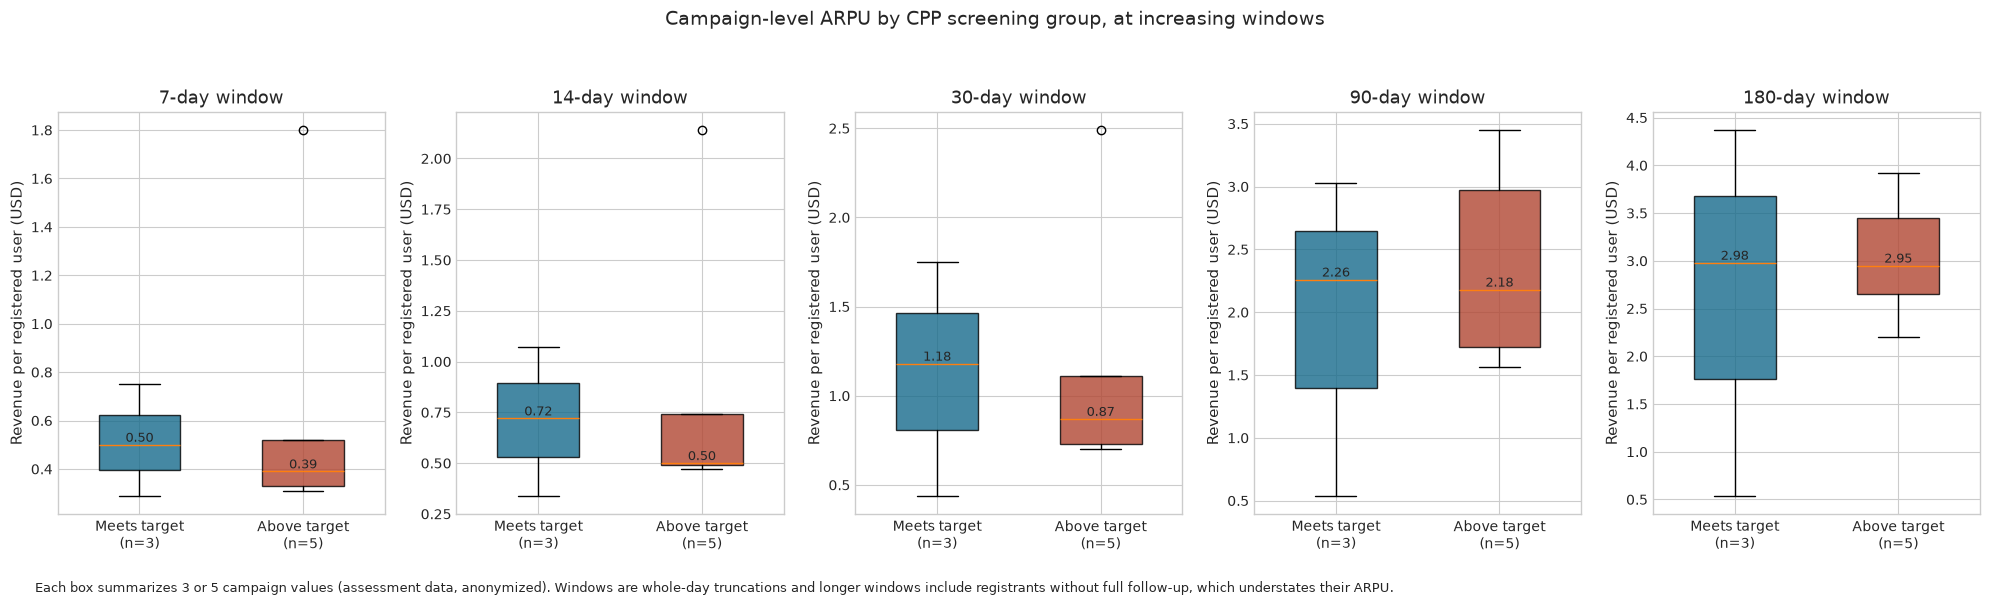

In [9]:
# ARPU distribution by CPP screening group at each window
fig, axes = plt.subplots(1, 5, figsize=(20, 6))

for ax, window in zip(axes, time_windows):
    column = f'{window} Days ARPU'
    groups = [
        arpu_report.loc[arpu_report['cpp_group'] == 'Meets target', column],
        arpu_report.loc[arpu_report['cpp_group'] == 'Above target', column],
    ]
    bp = ax.boxplot(groups, patch_artist=True, widths=0.5)
    ax.set_xticks([1, 2], ['Meets target\n(n=3)', 'Above target\n(n=5)'])
    for patch, key in zip(bp['boxes'], ['meets', 'above']):
        patch.set_facecolor(GROUP_COLORS[key])
        patch.set_alpha(0.8)
    for j, data in enumerate(groups):
        ax.text(j + 1, data.median(), f'{data.median():.2f}', ha='center', va='bottom', fontsize=9)
    ax.set_title(f'{window}-day window')
    ax.set_ylabel('Revenue per registered user (USD)')

fig.suptitle('Campaign-level ARPU by CPP screening group, at increasing windows', fontsize=14)
fig.text(0.02, 0.01,
         'Each box summarizes 3 or 5 campaign values (assessment data, anonymized). Windows are whole-day '
         'truncations and longer windows include registrants without full follow-up, which understates their ARPU.',
         fontsize=9)
fig.tight_layout(rect=(0, 0.05, 1, 0.93))
plt.show()


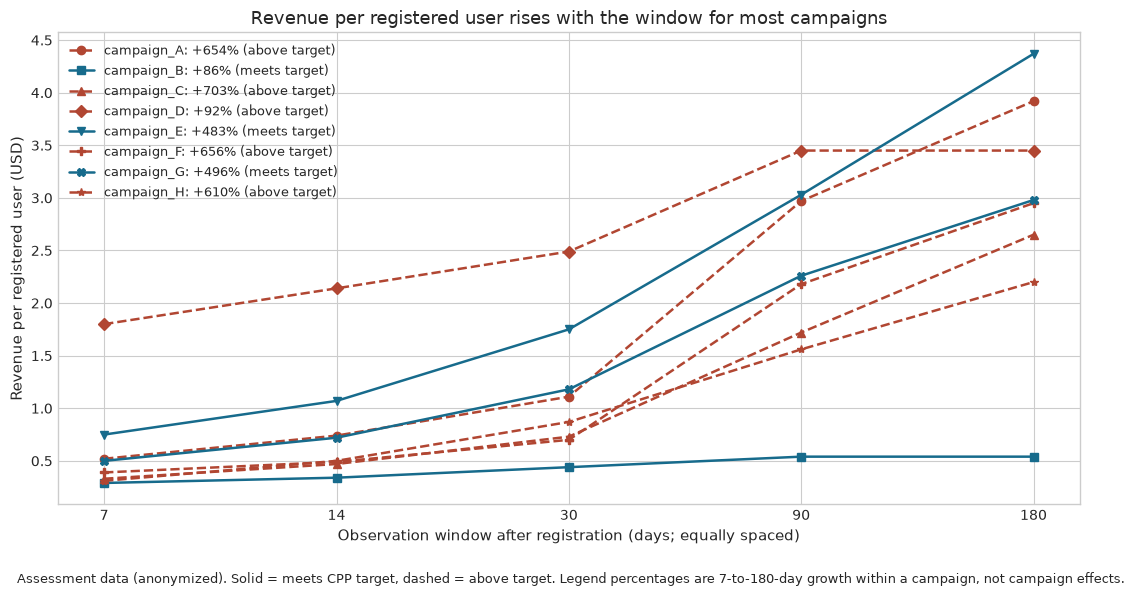

In [10]:
# Revenue per registered user by window, one line per campaign
markers = ['o', 's', '^', 'D', 'v', 'P', 'X', '*']
positions = np.arange(len(time_windows))

fig, ax = plt.subplots(figsize=(11, 6))
for marker, campaign in zip(markers, sorted(arpu_report['campaign'].unique())):
    row = arpu_report[arpu_report['campaign'] == campaign].iloc[0]
    key = 'meets' if row['cpp_group'] == 'Meets target' else 'above'
    values = [row[f'{window} Days ARPU'] for window in time_windows]
    growth = (values[-1] - values[0]) / values[0] * 100 if values[0] > 0 else 0
    ax.plot(positions, values, marker=marker, color=GROUP_COLORS[key],
            linestyle='-' if key == 'meets' else '--', linewidth=1.8, markersize=6,
            label=f'{campaign}: {growth:+.0f}% ({row["cpp_group"].lower()})')

ax.set_xticks(positions, [str(window) for window in time_windows])
ax.set_xlabel('Observation window after registration (days; equally spaced)')
ax.set_ylabel('Revenue per registered user (USD)')
ax.set_title('Revenue per registered user rises with the window for most campaigns')
ax.legend(loc='upper left', fontsize=9, frameon=False)
fig.text(0.02, 0.02,
         'Assessment data (anonymized). Solid = meets CPP target, dashed = above target. '
         'Legend percentages are 7-to-180-day growth within a campaign, not campaign effects.',
         fontsize=9)
fig.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()


The notebook's reported outputs show higher longer-window revenue per registered user for Campaigns A and C than their initial CPP labels would suggest, while Campaign B appears flatter (0.29 to 0.54 USD between the 7- and 180-day windows). Treat this pattern as exploratory until the revenue windows, mature-cohort coverage, and campaign-level denominators are validated.

The two seven-day ARPU values in this notebook differ by definition: this section truncates elapsed time to whole days and reports $0.75 for Campaign E, while section 3 uses a strict 168-hour window and reports $0.68 for the same campaign. The window rule, not the data, explains the gap.

A low day-7 CPP and a higher later revenue measure answer different questions. Compare them on compatible cohorts before changing spend.


### Funnel conversion, top to bottom

The interactive site pools each screening group's stage counts and plots every stage as the share of the group's own impressions that still converts — the same numbers as the table above, read as bars per group. Each bar is labeled with its share; the smallest stages are barely visible at this scale and the labels carry the numbers. Descriptive: the groups pool different campaigns, and nothing here is a causal comparison.

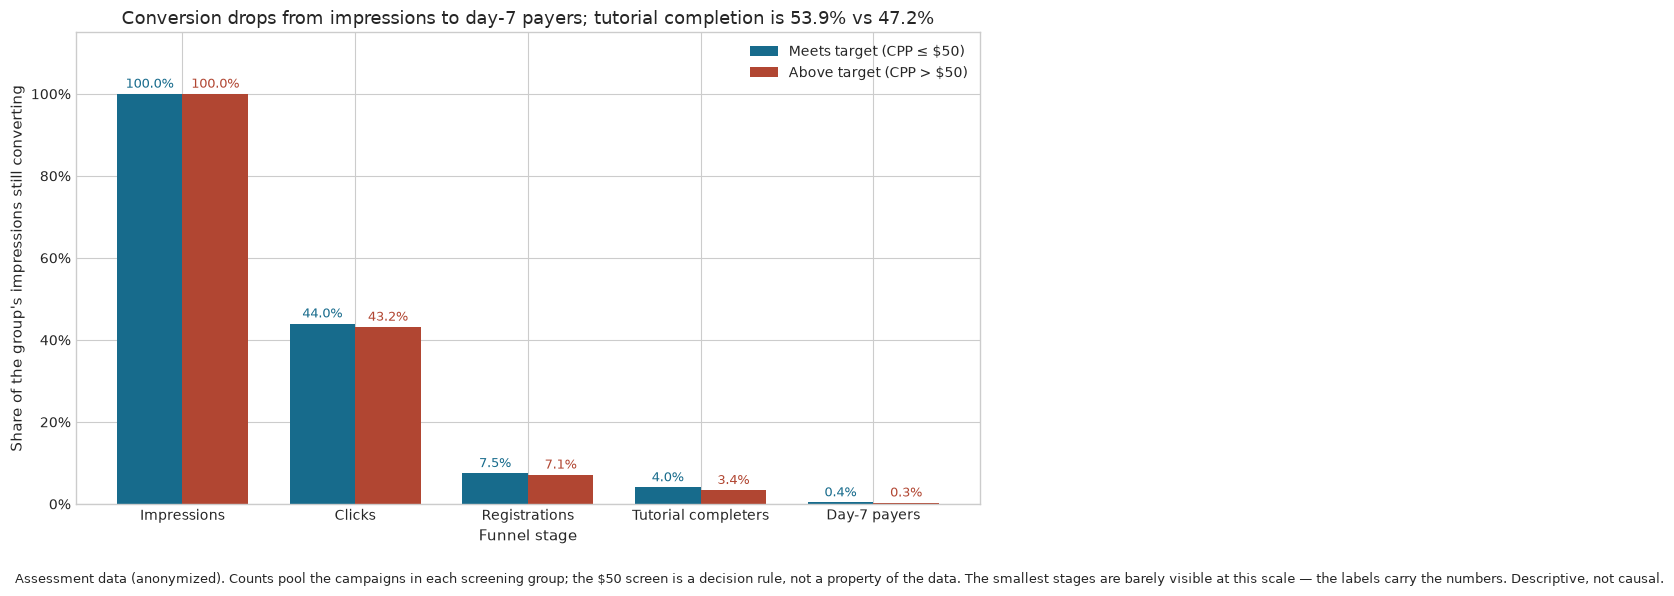

Meets target (CPP ≤ $50): Clicks 44.0%, Registrations 17.0%, Tutorial completers 53.9%, Day-7 payers 9.1%
Above target (CPP > $50): Clicks 43.2%, Registrations 16.5%, Tutorial completers 47.2%, Day-7 payers 9.2%


In [11]:
# Site figure: pooled funnel conversion at the $50 screen. Each bar is the
# share of the group's own impressions that still converts at that stage.
from matplotlib.ticker import PercentFormatter

stage_names = ['Impressions', 'Clicks', 'Registrations', 'Tutorial completers', 'Day-7 payers']
counts = {
    'Meets target (CPP ≤ $50)': [effective_impressions, effective_clicks, effective_registrations,
                                 effective_tutorial_completions, effective_day7_payers],
    'Above target (CPP > $50)': [ineffective_impressions, ineffective_clicks, ineffective_registrations,
                                 ineffective_tutorial_completions, ineffective_day7_payers],
}

fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(stage_names))
width = 0.38
for offset, (label, cs) in zip([-width / 2, width / 2], counts.items()):
    key = 'meets' if label.startswith('Meets') else 'above'
    shares = [c / cs[0] for c in cs]
    bars = ax.bar(x + offset, shares, width, color=GROUP_COLORS[key], label=label)
    for bar, s in zip(bars, shares):
        ax.text(bar.get_x() + bar.get_width() / 2, s + 0.015, f'{s:.1%}',
                ha='center', fontsize=9, color=GROUP_COLORS[key])
ax.set_xticks(x, stage_names)
ax.set_ylim(0, 1.15)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_title('Conversion drops from impressions to day-7 payers; tutorial completion '
             f"is {counts['Meets target (CPP ≤ $50)'][3] / counts['Meets target (CPP ≤ $50)'][2]:.1%} "
             f"vs {counts['Above target (CPP > $50)'][3] / counts['Above target (CPP > $50)'][2]:.1%}")
ax.set_ylabel("Share of the group's impressions still converting")
ax.set_xlabel('Funnel stage')
ax.legend(frameon=False)
fig.text(0.02, 0.02,
         'Assessment data (anonymized). Counts pool the campaigns in each screening group; the $50 '
         'screen is a decision rule, not a property of the data. The smallest stages are barely '
         'visible at this scale — the labels carry the numbers. Descriptive, not causal.',
         fontsize=9)
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

for label, cs in counts.items():
    steps = ', '.join(f'{stage_names[i]} {cs[i] / cs[i - 1]:.1%}' for i in range(1, 5))
    print(f'{label}: {steps}')

### Blended revenue per registered user across windows

One line per campaign answers whether the ranking holds; the bold line is the blended ARPU across the eight campaigns, weighted by campaign registrations. It is what a single top-line report would show if it ignored the campaign split — the number a summary slide would quote while the campaign lines move around it.

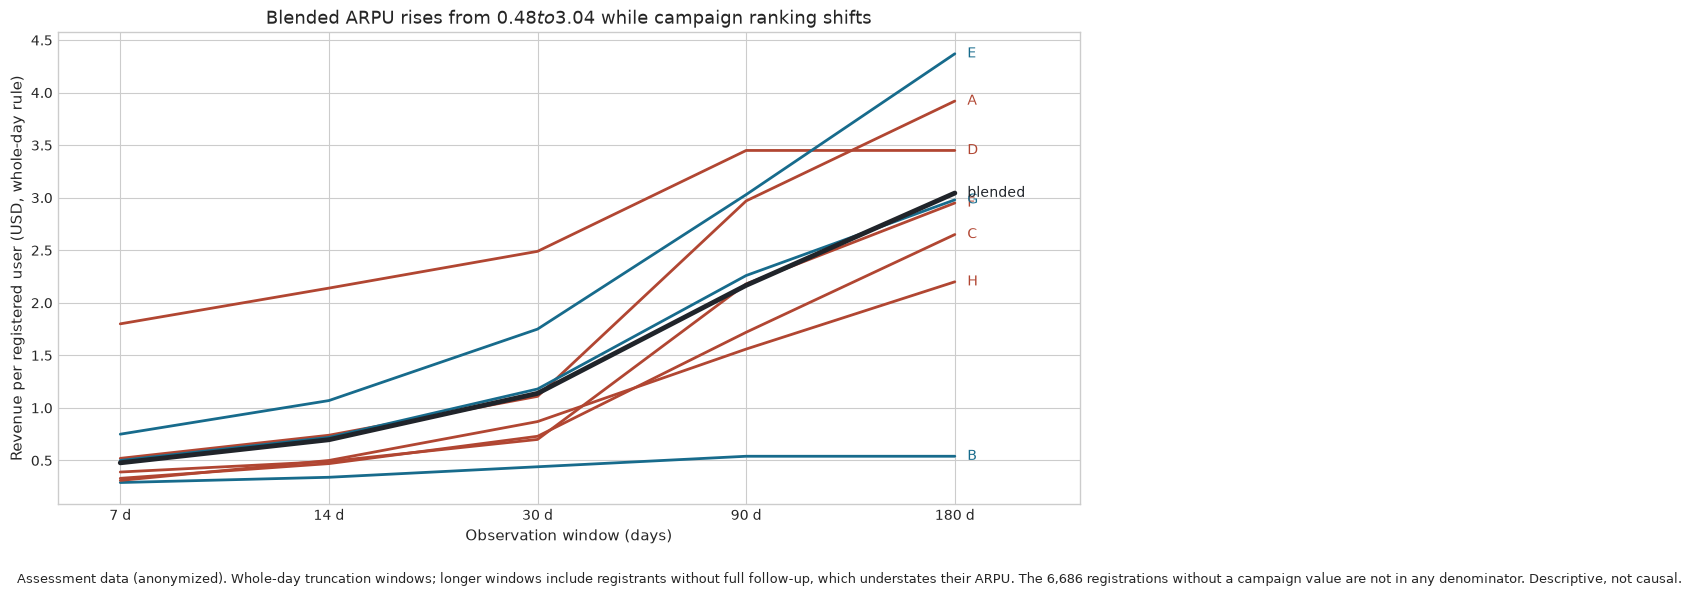

Blended ARPU (weighted by campaign registrations): 7 d $0.48, 14 d $0.70, 30 d $1.14, 90 d $2.17, 180 d $3.04


In [12]:
# Site figure: ARPU by observation window, one line per campaign (color = screen
# group) plus the revenue-weighted blend across all eight campaigns.
campaign_letters = {c: c.split('_')[-1] for c in arpu_report['campaign']}
campaign_regs = registration.groupby('campaign')['id'].nunique()
if not set(arpu_report['campaign']).issubset(campaign_regs.index):
    campaign_regs.index = [str(c).split('_')[-1] for c in campaign_regs.index]
total_regs = sum(campaign_regs[c] for c in arpu_report['campaign'])
assert total_regs > 0

blended = []
for window in time_windows:
    column = f'{window} Days ARPU'
    revenue = sum(arpu_report.loc[arpu_report['campaign'] == c, column].iloc[0] * campaign_regs[c]
                  for c in arpu_report['campaign'])
    blended.append(revenue / total_regs)

fig, ax = plt.subplots(figsize=(11, 6))
for campaign in sorted(arpu_report['campaign'].unique()):
    row = arpu_report[arpu_report['campaign'] == campaign].iloc[0]
    key = 'meets' if row['cpp_group'] == 'Meets target' else 'above'
    values = [row[f'{window} Days ARPU'] for window in time_windows]
    ax.plot(positions, values, color=GROUP_COLORS[key], linewidth=2)
    ax.text(positions[-1] + 0.06, values[-1], campaign_letters[campaign],
            color=GROUP_COLORS[key], fontsize=10, va='center')
ax.plot(positions, blended, color='#20242a', linewidth=3.5)
ax.text(positions[-1] + 0.06, blended[-1], 'blended', color='#20242a', fontsize=10, va='center')
ax.set_title(f'Blended ARPU rises from ${blended[0]:.2f} to ${blended[-1]:.2f} while campaign ranking shifts')
ax.set_ylabel('Revenue per registered user (USD, whole-day rule)')
ax.set_xlabel('Observation window (days)')
ax.set_xticks(positions, [f'{w} d' for w in time_windows])
ax.set_xlim(-0.3, len(time_windows) - 1 + 0.6)
fig.text(0.02, 0.02,
         'Assessment data (anonymized). Whole-day truncation windows; longer windows include registrants '
         'without full follow-up, which understates their ARPU. The 6,686 registrations without a campaign '
         'value are not in any denominator. Descriptive, not causal.',
         fontsize=9)
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()
print('Blended ARPU (weighted by campaign registrations): ' +
      ', '.join(f'{w} d ${v:.2f}' for w, v in zip(time_windows, blended)))

## 3. Compare day-7 payment distributions for Campaigns E and H

The notebook compares user-level payment totals within seven days for Campaign E and H using a Mann–Whitney U test at α = 0.05. This test compares rank distributions; it is not a direct test of conversion rate, mean revenue, or campaign causality.

Campaigns were not randomly assigned. The comparison is observational, and the campaigns were highlighted after inspecting the same dataset. Treat the test as exploratory and account for this selection when interpreting its p-value.

In [13]:
registration_E = registration[registration['campaign'] == 'campaign_E']
registration_H = registration[registration['campaign'] == 'campaign_H']

merged_reg_pay_E = pd.merge(registration_E, payment, on='id', how='inner')
merged_reg_pay_H = pd.merge(registration_H, payment, on='id', how='inner')

merged_reg_pay_E['lifetime'] = merged_reg_pay_E['pay_ts'] - merged_reg_pay_E['reg_ts']
merged_reg_pay_H['lifetime'] = merged_reg_pay_H['pay_ts'] - merged_reg_pay_H['reg_ts']

day7_payments_E = merged_reg_pay_E[merged_reg_pay_E['lifetime'] <= pd.Timedelta(days=7)]
day7_payments_H = merged_reg_pay_H[merged_reg_pay_H['lifetime'] <= pd.Timedelta(days=7)]

total_revenue_E = day7_payments_E['payment'].sum()
num_users_E = registration_E['id'].nunique()
arpu_7_E = total_revenue_E / num_users_E if num_users_E > 0 else 0

total_revenue_H = day7_payments_H['payment'].sum()
num_users_H = registration_H['id'].nunique()
arpu_7_H = total_revenue_H / num_users_H if num_users_H > 0 else 0

print("ARPU7 Comparison: Campaigns E vs H")
print("=" * 50)
print(f"Campaign E ARPU7: ${arpu_7_E:.2f}")
print(f"Campaign H ARPU7: ${arpu_7_H:.2f}")
print(f"Difference: ${arpu_7_E - arpu_7_H:.2f} ({((arpu_7_E - arpu_7_H)/arpu_7_H*100):.1f}%)")

ARPU7 Comparison: Campaigns E vs H
Campaign E ARPU7: $0.68
Campaign H ARPU7: $0.29
Difference: $0.39 (133.7%)


In [14]:
all_users_E = registration[registration['campaign'] == 'campaign_E']['id'].unique()
all_users_H = registration[registration['campaign'] == 'campaign_H']['id'].unique()

user_payments_E = merged_reg_pay_E[merged_reg_pay_E['lifetime'] <= pd.Timedelta(days=7)].groupby('id')['payment'].sum().reset_index()
user_payments_E = user_payments_E.rename(columns={'payment': '7_day_payment'})

user_arpu_E_df = pd.DataFrame({'id': all_users_E})
user_arpu_E_df = pd.merge(user_arpu_E_df, user_payments_E, on='id', how='left').fillna(0)
user_arpu_E = user_arpu_E_df['7_day_payment'].values

user_payments_H = merged_reg_pay_H[merged_reg_pay_H['lifetime'] <= pd.Timedelta(days=7)].groupby('id')['payment'].sum().reset_index()
user_payments_H = user_payments_H.rename(columns={'payment': '7_day_payment'})

user_arpu_H_df = pd.DataFrame({'id': all_users_H})
user_arpu_H_df = pd.merge(user_arpu_H_df, user_payments_H, on='id', how='left').fillna(0)
user_arpu_H = user_arpu_H_df['7_day_payment'].values


# Shapiro-Wilk test for normality
shapiro_E_stat, shapiro_E_p = stats.shapiro(user_arpu_E)
shapiro_H_stat, shapiro_H_p = stats.shapiro(user_arpu_H)

print("Shapiro-Wilk Test for Normality (7-Day User Payments)")
print("=" * 50)
print(f"Campaign E: Statistic={shapiro_E_stat:.4f}, p-value={shapiro_E_p:.4f}")
print(f"Campaign H: Statistic={shapiro_H_stat:.4f}, p-value={shapiro_H_p:.4f}")
print("\nInterpretation: \nIf p-value < 0.05, reject null hypothesis of normality.")


# Mann-Whitney U test
u_statistic, p_value = stats.mannwhitneyu(user_arpu_E, user_arpu_H, alternative='two-sided')

print("\nMann-Whitney U Test (Comparing 7-Day User Payments)")
print("=" * 50)
print(f"U Statistic: {u_statistic:.2f}")
print(f"P-value: {p_value:.4f}")

alpha = 0.05
if p_value < alpha:
    print(f"\nConclusion: \nReject the null hypothesis. \nThere is a statistically significant difference (p < {alpha}) in the 7-day payment distributions between Campaign E and Campaign H.")
else:
    print(f"\nConclusion: \nFail to reject the null hypothesis. \nThere is no statistically significant difference (p >= {alpha}) in the 7-day payment distributions between Campaign E and Campaign H.")

Shapiro-Wilk Test for Normality (7-Day User Payments)
Campaign E: Statistic=0.0307, p-value=0.0000
Campaign H: Statistic=0.0137, p-value=0.0000

Interpretation: 
If p-value < 0.05, reject null hypothesis of normality.

Mann-Whitney U Test (Comparing 7-Day User Payments)
U Statistic: 66360670.00
P-value: 0.0007

Conclusion: 
Reject the null hypothesis. 
There is a statistically significant difference (p < 0.05) in the 7-day payment distributions between Campaign E and Campaign H.


/tmp/portfolio-venv/lib64/python3.14/site-packages/scipy/stats/_axis_nan_policy.py:601: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 9447.
  res = hypotest_fun_out(*samples, **kwds)
/tmp/portfolio-venv/lib64/python3.14/site-packages/scipy/stats/_axis_nan_policy.py:601: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 13920.
  res = hypotest_fun_out(*samples, **kwds)


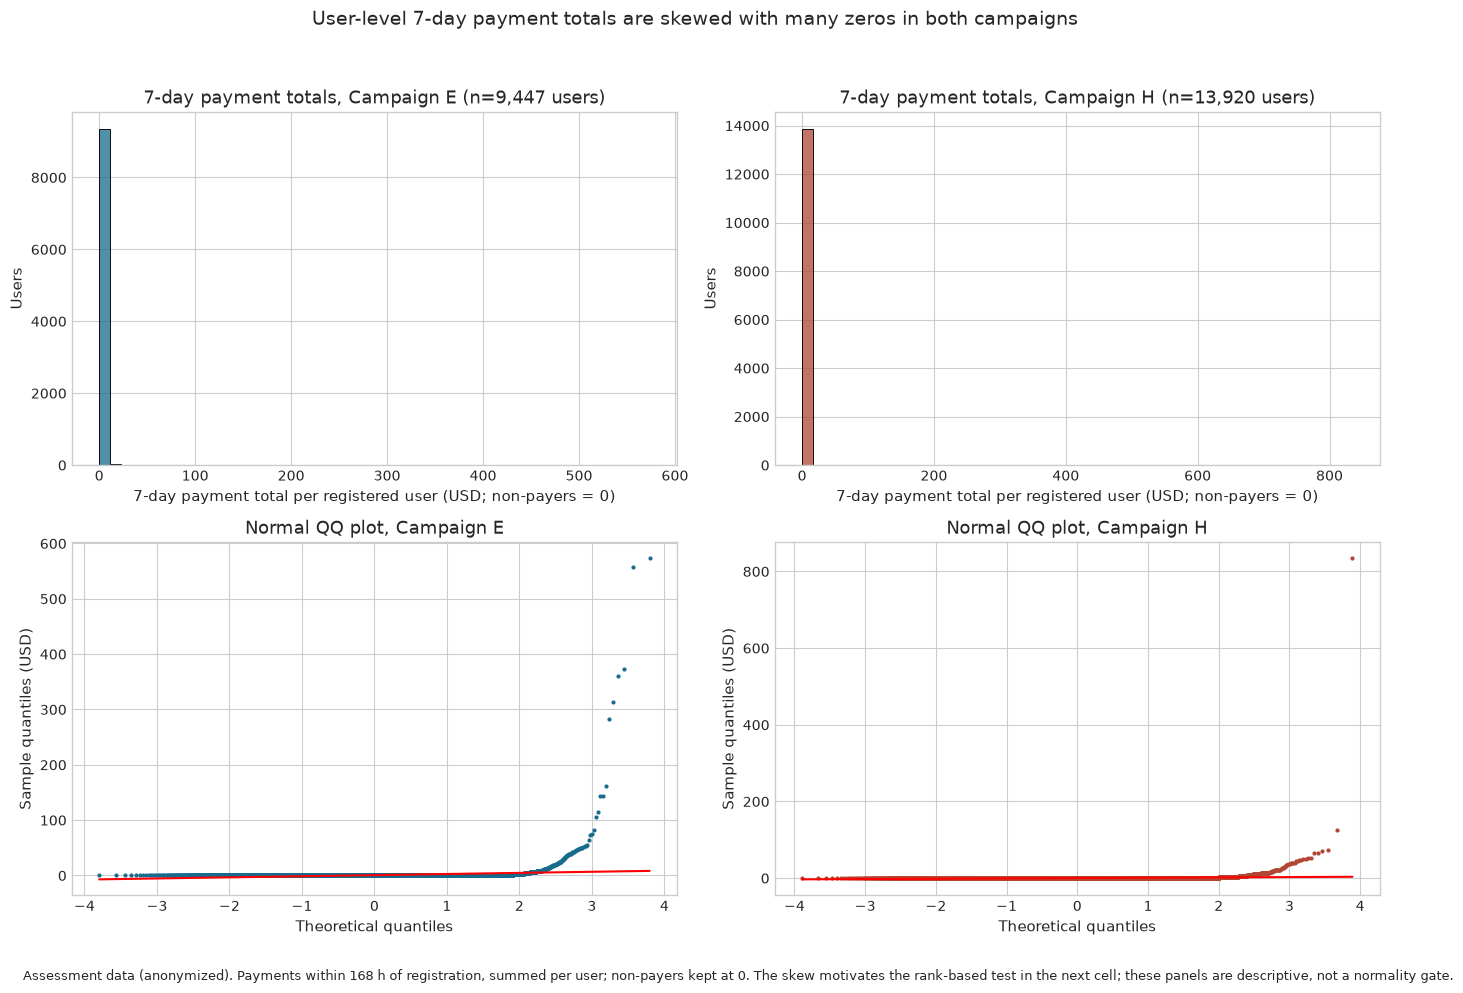

In [15]:
# Distribution diagnostics for the user-level 7-day payment totals
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, values, campaign, key in [
    (axes[0, 0], user_arpu_E, 'Campaign E', 'meets'),
    (axes[0, 1], user_arpu_H, 'Campaign H', 'above'),
]:
    sns.histplot(values, ax=ax, color=GROUP_COLORS[key], bins=50)
    ax.set_title(f'7-day payment totals, {campaign} (n={len(values):,} users)')
    ax.set_xlabel('7-day payment total per registered user (USD; non-payers = 0)')
    ax.set_ylabel('Users')

for ax, values, campaign, key in [
    (axes[1, 0], user_arpu_E, 'Campaign E', 'meets'),
    (axes[1, 1], user_arpu_H, 'Campaign H', 'above'),
]:
    stats.probplot(values, dist="norm", plot=ax)
    ax.get_lines()[0].set(marker='o', markersize=2, color=GROUP_COLORS[key], linestyle='none')
    ax.set_title(f'Normal QQ plot, {campaign}')
    ax.set_xlabel('Theoretical quantiles')
    ax.set_ylabel('Sample quantiles (USD)')

fig.suptitle('User-level 7-day payment totals are skewed with many zeros in both campaigns', fontsize=14)
fig.text(0.02, 0.01,
         'Assessment data (anonymized). Payments within 168 h of registration, summed per user; non-payers kept at 0. '
         'The skew motivates the rank-based test in the next cell; these panels are descriptive, not a normality gate.',
         fontsize=9)
fig.tight_layout(rect=(0, 0.04, 1, 0.95))
plt.show()


### Statistical result: interpret with care

The output above reports p ≈ 0.0007 for the Mann–Whitney comparison. If the test inputs and assumptions are correct, this is evidence against identical rank distributions in this sample. It does not establish that Campaign E caused better monetization, nor does it validate the $50 CPP threshold.

The Shapiro–Wilk output is descriptive only, and the samples (9,447 and 13,920 users) exceed the size for which scipy reports accurate p-values. The rank-based test does not require a normality gate, and the payment totals are skewed with many zeros.

Before using the result, verify that the user-level data include non-payers as zero, exclude payments outside the seven-day window and before registration, and use fully observed cohorts. Report an effect size and confidence interval alongside the p-value.


### How much do the two distributions overlap?

The interactive site adds a descriptive overlap view: one dot per paying user's 7-day total with median boxes, and smoothed distributions of the two payer groups with their shared area shaded. The overlap is the honest companion to the p-value above — with 23,367 user totals the rank test registers the small payer-share gap even though the distribution shapes sit almost on top of each other. Statistical significance is not separation.

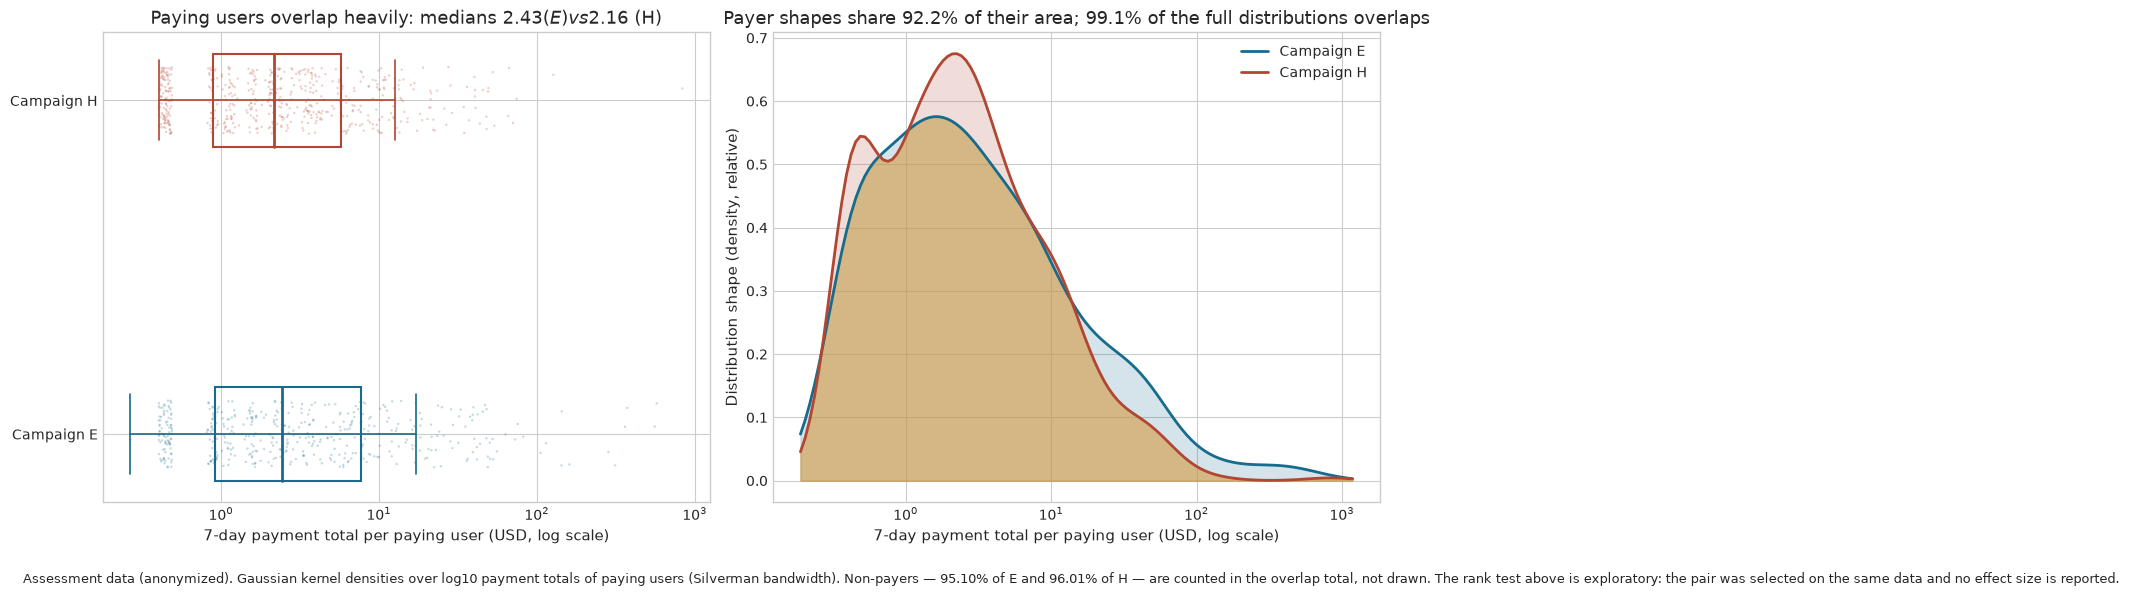

Payer share: 4.90% (E) vs 3.99% (H) of 23,367 user totals
Overlap of payer shapes: 92.2%; including the non-payer mass: 99.1%


In [16]:
# Site figures: paying-user totals (box + strip) and smoothed distributions with
# the shared area shaded. Same rules as the site: Gaussian KDE over log10 totals,
# Silverman bandwidth, rectangle-rule overlap on a 120-point grid. Deterministic
# jitter seed so the figure is reproducible.
rng = np.random.default_rng(481516)
e_pay = np.sort(user_arpu_E[user_arpu_E > 0])
h_pay = np.sort(user_arpu_H[user_arpu_H > 0])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ax = axes[0]
for ypos, (vals, name, key) in enumerate([(e_pay, 'Campaign E', 'meets'), (h_pay, 'Campaign H', 'above')]):
    c = GROUP_COLORS[key]
    q1, med, q3 = np.percentile(vals, [25, 50, 75])
    iqr = q3 - q1
    lo_w = vals[vals >= q1 - 1.5 * iqr].min()
    hi_w = vals[vals <= q3 + 1.5 * iqr].max()
    ax.add_patch(plt.Rectangle((q1, ypos - 0.14), q3 - q1, 0.28, fill=False, edgecolor=c, linewidth=1.5))
    ax.plot([med, med], [ypos - 0.14, ypos + 0.14], color=c, linewidth=2)
    ax.plot([lo_w, hi_w], [ypos, ypos], color=c, linewidth=1.2)
    for w in (lo_w, hi_w):
        ax.plot([w, w], [ypos - 0.12, ypos + 0.12], color=c, linewidth=1.2)
    jitter = rng.uniform(-0.10, 0.10, size=len(vals))
    ax.scatter(vals, np.full(len(vals), ypos) + jitter, s=3, alpha=0.25, color=c, edgecolors='none')
ax.set_yticks([0, 1], ['Campaign E', 'Campaign H'])
ax.set_xscale('log')
ax.set_xlabel('7-day payment total per paying user (USD, log scale)')
ax.set_title(f'Paying users overlap heavily: medians ${np.median(e_pay):.2f} (E) vs ${np.median(h_pay):.2f} (H)')

def kde_log10(vals, grid):
    lx = np.log10(vals)
    bw = 1.06 * lx.std(ddof=1) * len(lx) ** -0.2
    z = (grid[:, None] - lx[None, :]) / bw
    return np.exp(-0.5 * z ** 2).sum(axis=1) / (len(lx) * bw * np.sqrt(2 * np.pi))

lo = np.log10(np.concatenate([e_pay, h_pay])).min() - 0.15
hi = np.log10(np.concatenate([e_pay, h_pay])).max() + 0.15
grid = np.linspace(lo, hi, 121)
fe, fh = kde_log10(e_pay, grid), kde_log10(h_pay, grid)
x = 10 ** grid
d = grid[1] - grid[0]
overlap_payers = np.minimum(fe, fh).sum() * d
pe, ph = len(e_pay) / len(user_arpu_E), len(h_pay) / len(user_arpu_H)
overlap_all = min(1 - pe, 1 - ph) + np.minimum(pe * fe, ph * fh).sum() * d

ax = axes[1]
ax.fill_between(x, fe, 0, color=GROUP_COLORS['meets'], alpha=0.18)
ax.fill_between(x, fh, 0, color=GROUP_COLORS['above'], alpha=0.18)
ax.fill_between(x, np.minimum(fe, fh), 0, color='#dda944', alpha=0.5)
ax.plot(x, fe, color=GROUP_COLORS['meets'], linewidth=2, label='Campaign E')
ax.plot(x, fh, color=GROUP_COLORS['above'], linewidth=2, label='Campaign H')
ax.set_xscale('log')
ax.set_xlabel('7-day payment total per paying user (USD, log scale)')
ax.set_ylabel('Distribution shape (density, relative)')
ax.legend(frameon=False)
ax.set_title(f'Payer shapes share {overlap_payers:.1%} of their area; '
             f'{overlap_all:.1%} of the full distributions overlaps')
fig.text(0.02, 0.02,
         f'Assessment data (anonymized). Gaussian kernel densities over log10 payment totals of paying '
         f'users (Silverman bandwidth). Non-payers — {(1 - pe):.2%} of E and {(1 - ph):.2%} of H — are '
         f'counted in the overlap total, not drawn. The rank test above is exploratory: the pair was '
         f'selected on the same data and no effect size is reported.',
         fontsize=9)
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

print(f'Payer share: {pe:.2%} (E) vs {ph:.2%} (H) of {len(user_arpu_E) + len(user_arpu_H):,} user totals')
print(f'Overlap of payer shapes: {overlap_payers:.1%}; including the non-payer mass: {overlap_all:.1%}')

## 4. Proposed randomized creative test

The notebook proposes testing a new creative against the current Campaign E creative, with a 20% relative increase in day-3 payer conversion as the target effect. This is a proposed design, not a result.

- **Hypothesis:** the new creative increases the share of eligible users who pay within 72 hours of registration.
- **Primary metric:** day-3 payer conversion, with the eligible assigned user as the denominator.
- **Target effect:** 20% relative lift over the validated baseline.
- **Planning assumptions:** 5% significance level and 80% power.

Before launch, define the randomization unit and exposure event, ensure assignment is stable, set guardrails and a stopping rule, and confirm that users have a complete 72-hour outcome window.

In [17]:
# Calculate baseline Day 3 conversion rate for Campaign E
registration_E = registration[registration['campaign'] == 'campaign_E']
merged_reg_pay_E = pd.merge(registration_E, payment, on='id', how='inner')
merged_reg_pay_E['lifetime'] = merged_reg_pay_E['pay_ts'] - merged_reg_pay_E['reg_ts']

day3_payments_E = merged_reg_pay_E[merged_reg_pay_E['lifetime'] <= pd.Timedelta(days=3)]
day3_payers_E_count = day3_payments_E['id'].nunique()
total_registrations_E = registration_E['id'].nunique()

baseline_day3_conversion_rate = day3_payers_E_count / total_registrations_E if total_registrations_E > 0 else 0

desired_relative_uplift = 0.20
target_day3_conversion_rate = baseline_day3_conversion_rate * (1 + desired_relative_uplift)

print("A/B Test Parameters")
print("=" * 50)
print(f"Baseline Day 3 Conversion Rate: {baseline_day3_conversion_rate:.4f} ({baseline_day3_conversion_rate:.2%})")
print(f"Target Day 3 Conversion Rate: {target_day3_conversion_rate:.4f} ({target_day3_conversion_rate:.2%})")
print(f"Desired Uplift: {desired_relative_uplift:.1%}")

# Calculate effect size for a one-sided test expecting an increase
effect_size = proportion_effectsize(baseline_day3_conversion_rate, target_day3_conversion_rate)
# Ensure effect size is positive for the 'larger' alternative
effect_size = abs(effect_size)

alpha = 0.05
power = 0.80

# 1-sided test since we're testing for improvement
sample_size_needed_per_group = zt_ind_solve_power(
    effect_size=effect_size,
    alpha=alpha,
    power=power,
    alternative='larger'
)

total_sample_size_needed = sample_size_needed_per_group * 2

print(f"\nSample Size Calculation")
print("=" * 50)
print(f"Effect Size: {effect_size:.4f}")
print(f"Statistical Power: {power:.1%}")
print(f"Significance Level: {alpha:.1%}")
print(f"Required Sample Size per Group: {sample_size_needed_per_group:.0f}")
print(f"Total Sample Size (both groups): {total_sample_size_needed:.0f}")

# Estimate test duration, assuming 1000 daily registrations. Should be adjusted based on actual traffic
estimated_daily_registrations = 1000
estimated_days = total_sample_size_needed / estimated_daily_registrations

print(f"\nTest Duration Estimate")
print("=" * 50)
print(f"Assumed Daily Registrations: {estimated_daily_registrations:,}")
print(f"Estimated Test Duration: {estimated_days:.1f} days")

A/B Test Parameters
Baseline Day 3 Conversion Rate: 0.0417 (4.17%)
Target Day 3 Conversion Rate: 0.0500 (5.00%)
Desired Uplift: 20.0%

Sample Size Calculation
Effect Size: 0.0399
Statistical Power: 80.0%
Significance Level: 5.0%
Required Sample Size per Group: 7764
Total Sample Size (both groups): 15527

Test Duration Estimate
Assumed Daily Registrations: 1,000
Estimated Test Duration: 15.5 days


A launch decision should use the pre-specified primary metric and guardrails, not statistical significance alone. Check assignment balance, exposure logging, sample size, and the full outcome window before reading the result. A test of an ad creative also needs a clear randomization and delivery mechanism so the groups are comparable.

## 5. Cohort revenue query

The final analysis attempts to select users who registered from May 10–20 and completed the tutorial within seven days, then plot cumulative payment revenue by days after registration.

This query is an exploratory SQL example. Validate its date range, elapsed-time calculation, daily revenue aggregation, cumulative sum, and 100-day cohort maturity before interpreting the chart as LTV.

In [18]:
conn = sqlite3.connect(':memory:')
cursor = conn.cursor()

registration.to_sql('registration', conn, index=False, if_exists='replace')
tutorial.to_sql('tutorial', conn, index=False, if_exists='replace')
payment.to_sql('payment', conn, index=False, if_exists='replace')

# Open review item: payment revenue is not summed per day before the cumulative
# window, and strftime('%J') truncates elapsed time to whole days. The chart below
# renders this exploratory query as-is; it is not a validated LTV curve.
sql_query = """
WITH cohort AS (
    SELECT
        r.id,
        r.reg_ts,
        t.tut_ts
    FROM registration r
    JOIN tutorial t ON r.id = t.id
    WHERE r.date BETWEEN '2020-05-10' AND '2020-05-20'
        AND CAST((strftime('%s', t.tut_ts) - strftime('%s', r.reg_ts)) AS REAL) / (60 * 60) <= 168
),

payments AS (
    SELECT
        p.id,
        p.date AS date_pay,
        p.payment,
        CAST(strftime('%J', p.pay_ts) AS INTEGER) - CAST(strftime('%J', c.reg_ts) AS INTEGER) AS dar
    FROM payment p
    JOIN cohort c ON p.id = c.id
    WHERE CAST((strftime('%s', p.pay_ts) - strftime('%s', c.reg_ts)) AS REAL) / (60 * 60 * 24) <= 100
)

SELECT
    dar,
    SUM(payment) OVER (ORDER BY dar) AS revenue
FROM payments
GROUP BY dar
ORDER BY dar
"""

result_df = pd.read_sql_query(sql_query, conn)

print("Cohort Analysis: Cumulative Revenue Over 100 Days")
print("=" * 50)
print(result_df.head(10))

conn.close()

Cohort Analysis: Cumulative Revenue Over 100 Days
   dar   revenue
0    0  0.265862
1    1  0.696989
2    2  1.516430
3    3  1.954045
4    4  2.144192
5    5  2.647320
6    6  3.726996
7    7  4.225959
8    8  5.003428
9    9  5.446836


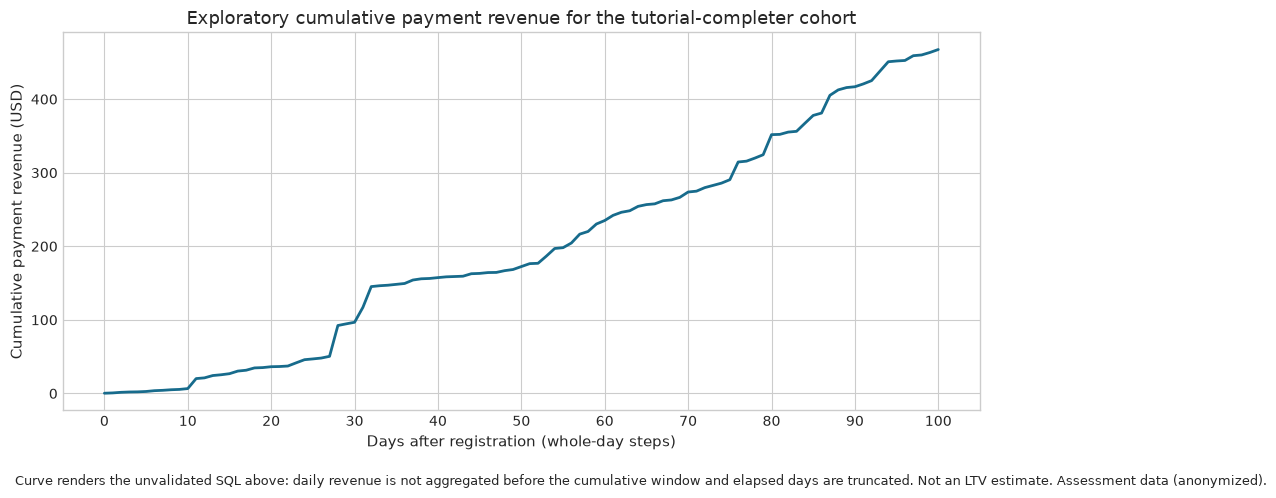

In [19]:
# Cumulative revenue curve produced by the exploratory SQL above
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(result_df['dar'], result_df['revenue'], color=GROUP_COLORS['meets'], linewidth=2)
ax.set_title('Exploratory cumulative payment revenue for the tutorial-completer cohort')
ax.set_xlabel('Days after registration (whole-day steps)')
ax.set_ylabel('Cumulative payment revenue (USD)')
ax.set_xticks(np.arange(0, 101, 10))
fig.text(0.02, 0.02,
         'Curve renders the unvalidated SQL above: daily revenue is not aggregated before the cumulative '
         'window and elapsed days are truncated. Not an LTV estimate. Assessment data (anonymized).',
         fontsize=9)
fig.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()


### Cohort facts behind the curve

The interactive site quotes three facts about the curve above: the cohort has 5,421 users, the effective registration range is May 10–19, and the curve ends near $467. Note the date filter: it compares datetimes as text, so rows from 2020-05-20 fall outside `BETWEEN '2020-05-10' AND '2020-05-20'` — the filter reads May 10 to May 20 but covers May 10 to May 19.

In [20]:
# Facts quoted on the site about the curve above: cohort size, the effective
# registration range, and the final cumulative value.
conn = sqlite3.connect(':memory:')
registration.to_sql('registration', conn, index=False, if_exists='replace')
tutorial.to_sql('tutorial', conn, index=False, if_exists='replace')
payment.to_sql('payment', conn, index=False, if_exists='replace')

facts_df = pd.read_sql_query('''
WITH cohort AS (
    SELECT
        r.id,
        r.reg_ts,
        t.tut_ts
    FROM registration r
    JOIN tutorial t ON r.id = t.id
    WHERE r.date BETWEEN '2020-05-10' AND '2020-05-20'
        AND CAST((strftime('%s', t.tut_ts) - strftime('%s', r.reg_ts)) AS REAL) / (60 * 60) <= 168
)
SELECT COUNT(DISTINCT id) AS cohort_users, MIN(reg_ts) AS first_reg, MAX(reg_ts) AS last_reg
FROM cohort
''', conn)
conn.close()

print(facts_df.to_string(index=False))
print(f"Final cumulative revenue after 100 whole-day steps: ${result_df['revenue'].iloc[-1]:,.2f}")

 cohort_users           first_reg            last_reg
         5421 2020-05-10 00:08:13 2020-05-19 23:59:16
Final cumulative revenue after 100 whole-day steps: $467.45


<a id='conclusions'></a>
## 6. Summary and next steps

The notebook raises useful questions about short-term acquisition cost, funnel behavior, and later player revenue. Its current outputs are exploratory because campaign costs, payer counts, observation windows, and cohort definitions have not yet been reconciled.

### What the analysis suggests checking

1. Recalculate CPP on matching campaign and registration dates, using only users with a complete seven-day window.
2. Validate each funnel numerator and denominator, and report counts with rates.
3. Recalculate revenue per registered player at fixed horizons using mature cohorts and one row per user before aggregation.
4. Replace the observational Campaign E/H comparison with a clearly defined estimand, an effect size, and uncertainty. Do not interpret it as a causal campaign effect.
5. Correct and validate the SQL cohort aggregation before using the plotted curve.
6. If the creative question matters, run a randomized test with stable assignment, an exposure definition, a primary metric, guardrails, and a stopping rule.
7. Confirm permission to publish the assessment CSVs in `data/`, or replace them with synthetic data before sharing the case.

### Decision

Do not use this notebook alone to increase or stop campaign spend. First validate the source data and calculations. Then compare cost and mature-cohort revenue on aligned populations. Use an experiment to estimate the impact of a creative change.